<a href="https://colab.research.google.com/github/nabillahumi/S5-Mesin_Learning/blob/main/UTS/KMEANS_Cosine.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
%pip install scikit-learn-extra

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 819.0/819.0 kB 15.7 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for scikit-learn-extra: filename=scikit_learn_extra-0.3.0-cp313-cp313-linux_x86_64.whl size=2154569 sha256=e2c3ee66863563853f473c66f386c2a7b2b83e68c9e77268a6e9c3176e5e3729
  Stored in directory: /root/.cache/pip/wheels/17/4b/b8/6b6711681d0981b110c9cc91ad6d1ebd88adf1547e1da301fc
Successfully built scikit-learn-extra


In [2]:
import time
import tracemalloc
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler, Normalizer
from sklearn_extra.cluster import KMedoids

# Lokasi data/output: berjalan dari root repo, machine_learning, atau experiments.
# Notebook tidak menyediakan __file__.
cwd = Path.cwd().resolve()
BASE_DIR = next(
    (base for parent in (cwd, *cwd.parents)
     for base in (parent / "machine_learning", parent)
     if (base / "experiments").is_dir() and (base / "data").is_dir()),
    None,
)

from pathlib import Path

DATA_PATH = Path("/content/cafes.csv")
FIGURES_DIR = Path("/content/reports/figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)


In [3]:
# ==============================================================================
# BAGIAN A: LOAD DATA & PREPROCESSING (MURNI FITUR NUMERIK KAFE)
# ==============================================================================
print("\n" + "="*56)
print("  BAGIAN A: LOAD DATA & PREPROCESSING")
print("="*56)

df = pd.read_csv(DATA_PATH, on_bad_lines="skip")

# Kolom fitur numerik kafe (sesuai instruksi: lokasi spasial & rating/ulasan)
kolom_fitur = ['latitude', 'longitude', 'rating', 'review_count']
kolom_ada = [k for k in kolom_fitur if k in df.columns]

# Ambil kolom numerik dan hapus baris bernilai kosong
df_fitur = df[kolom_ada].dropna()

# Standarisasi data dengan StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_fitur)

# Normalisasi L2 untuk Cosine distance (persis pola K_Means_Cosine.ipynb)
normalizer = Normalizer(norm='l2')
X_l2 = normalizer.fit_transform(X_scaled)

print(f"Data siap | Fitur: {kolom_ada}")
print(f"Bentuk Matriks (Shape): {X_scaled.shape} | Baris Sampel: {len(df_fitur)}")



  BAGIAN A: LOAD DATA & PREPROCESSING
Data siap | Fitur: ['latitude', 'longitude', 'rating', 'review_count']
Bentuk Matriks (Shape): (99, 4) | Baris Sampel: 99



  BAGIAN B: ELBOW METHOD (K=2 HINGGA 10)


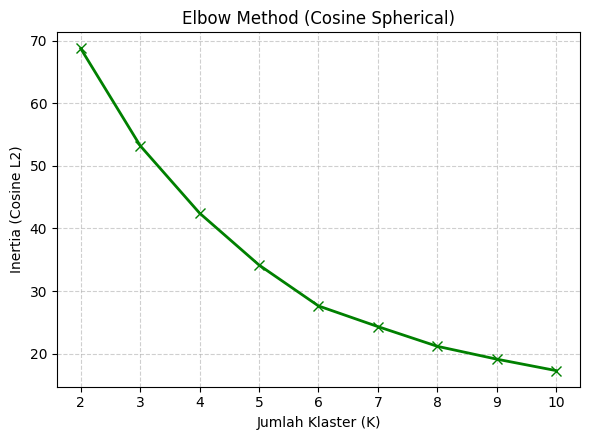

Grafik Elbow disimpan ke: /content/reports/figures/kmeans_cosine_elbow_plots.png


In [5]:
# ==============================================================================
# BAGIAN B: ELBOW METHOD (UNTUK MENENTUKAN K TERBAIK)
# ==============================================================================
print("\n" + "="*56)
print("  BAGIAN B: ELBOW METHOD (K=2 HINGGA 10)")
print("="*56)

K_range = range(2, 11)

# 3. Elbow Cosine (L2 Normalizer + KMeans)
sse_cosine = []
for k in K_range:
    km_c = KMeans(n_clusters=k, random_state=42, n_init=10)
    km_c.fit(X_l2)
    sse_cosine.append(km_c.inertia_)


plt.figure(figsize=(6, 4.5))
plt.plot(list(K_range), sse_cosine, 'gx-', linewidth=2, markersize=7)
plt.xlabel('Jumlah Klaster (K)')
plt.ylabel('Inertia (Cosine L2)')
plt.title('Elbow Method (Cosine Spherical)')
plt.xticks(list(K_range))
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
elbow_plot_path = FIGURES_DIR / "kmeans_cosine_elbow_plots.png"
plt.savefig(elbow_plot_path, dpi=150)
plt.show()
plt.close()
print(f"Grafik Elbow disimpan ke: {elbow_plot_path}")

# Nilai K terbaik sesuai file asli
K_TERBAIK_COS = 4


In [6]:
# --- 3. K-MEANS COSINE ---
print("\n" + "="*56)
print("  K-MEANS — METRIK: COSINE (L2-NORMALIZED)")
print("="*56)
tracemalloc.start()
t_mulai = time.time()

km_cosine = KMeans(n_clusters=K_TERBAIK_COS, random_state=42, n_init=10)
lbl_cosine = km_cosine.fit_predict(X_l2)

t_selesai = time.time()
_, mem_puncak = tracemalloc.get_traced_memory()
tracemalloc.stop()

sil_cosine = silhouette_score(X_l2, lbl_cosine, metric='cosine')
waktu_cos = t_selesai - t_mulai
mem_cos_kb = mem_puncak / 1024
mem_cos_mb = mem_puncak / (1024**2)

print(f"  Jumlah Klaster    : {K_TERBAIK_COS}")
print(f"  Waktu Eksekusi    : {waktu_cos:.4f} detik")
print(f"  Memori Puncak     : {mem_cos_kb:.2f} KB ({mem_cos_mb:.4f} MB)")
print(f"  Silhouette Score  : {sil_cosine:.4f}")
print("="*56)



  K-MEANS — METRIK: COSINE (L2-NORMALIZED)
  Jumlah Klaster    : 4
  Waktu Eksekusi    : 0.0973 detik
  Memori Puncak     : 3953.58 KB (3.8609 MB)
  Silhouette Score  : 0.4837



  BAGIAN D: VISUALISASI PCA 2D (K-MEANS)


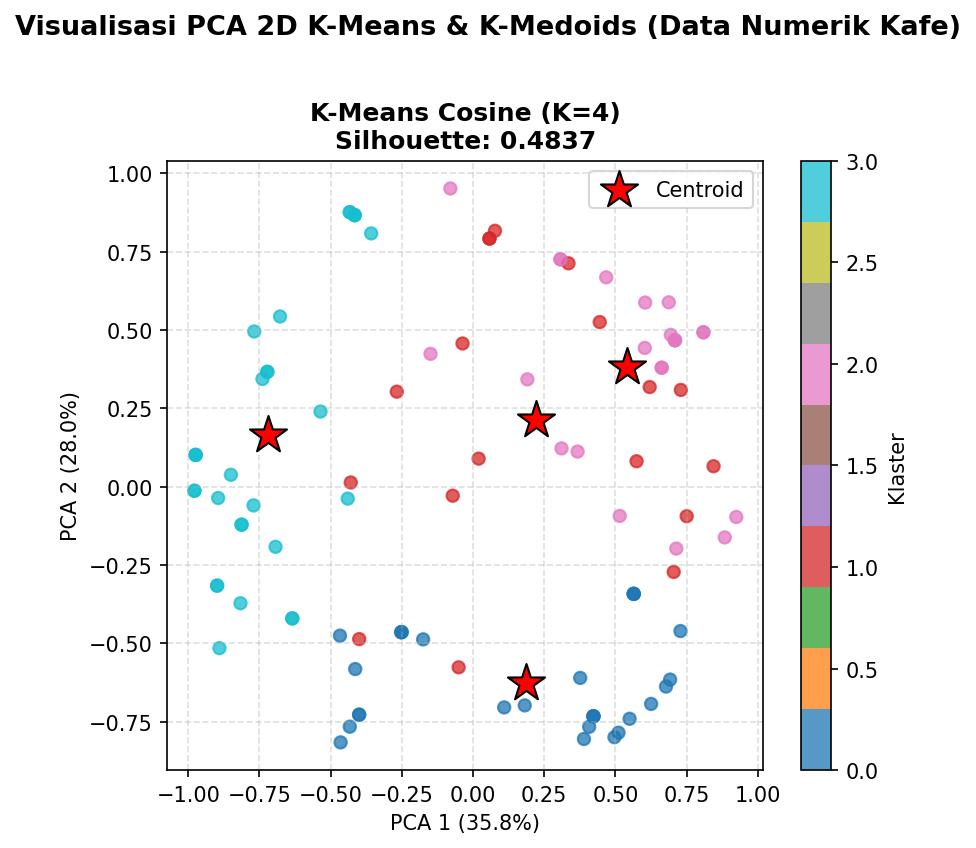

Visualisasi PCA disimpan ke: /content/reports/figures/kmeans_cosine_pca_plots.png


In [7]:
# ==============================================================================
# BAGIAN D: VISUALISASI PCA 2D DENGAN CENTROID BINTANG MERAH
# ==============================================================================
print("\n" + "="*56)
print("  BAGIAN D: VISUALISASI PCA 2D (K-MEANS)")
print("="*56)

pca_l2 = PCA(n_components=2, random_state=42)
X_pca_l2 = pca_l2.fit_transform(X_l2)
v1_l2, v2_l2 = pca_l2.explained_variance_ratio_ * 100

fig, ax = plt.subplots(figsize=(6, 5.5), dpi=150)
axes = [ax]
# 3. Plot Cosine
cen_c = pca_l2.transform(km_cosine.cluster_centers_)
sc3 = axes[0].scatter(X_pca_l2[:, 0], X_pca_l2[:, 1], c=lbl_cosine, cmap='tab10', s=35, alpha=0.75)
axes[0].scatter(cen_c[:, 0], cen_c[:, 1], c='red', marker='*', s=350, zorder=5, label='Centroid', edgecolors='black')
axes[0].set_title(f"K-Means Cosine (K={K_TERBAIK_COS})\nSilhouette: {sil_cosine:.4f}", fontweight='bold')
axes[0].set_xlabel(f'PCA 1 ({v1_l2:.1f}%)')
axes[0].set_ylabel(f'PCA 2 ({v2_l2:.1f}%)')
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.4)
plt.colorbar(sc3, ax=axes[0], label='Klaster')

plt.suptitle("Visualisasi PCA 2D K-Means & K-Medoids (Data Numerik Kafe)", fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
pca_plot_path = FIGURES_DIR / "kmeans_cosine_pca_plots.png"
plt.savefig(pca_plot_path, dpi=150, bbox_inches='tight')
plt.show()
plt.close()
print(f"Visualisasi PCA disimpan ke: {pca_plot_path}")


In [8]:
# Dictionary ringkasan performa untuk pelaporan
KMEANS_SUMMARY = {
    "cosine": {
        "algo": "K-Means", "metric": "Cosine", "param": f"K={K_TERBAIK_COS}",
        "time": waktu_cos, "mem_mb": mem_cos_mb, "clusters": K_TERBAIK_COS,
        "noise_pct": 0.0, "silhouette": sil_cosine, "labels": lbl_cosine
    }
}
